# P2.02 — What moves affordability within a municipality? Fixed-effects regressions

**Questions:** RQ3.3 (population growth and prices; immigration is not in the panel yet), RQ5.1 and RQ5.4
(short-term rentals and prices, separated from the other drivers).

**Outcome:** log price-to-income (`log_pti`), the affordability indicator of p1. Coefficients times 100 are
percentage changes. **Drivers:** population growth, completed dwellings in the previous three years per 1,000
dwellings, share of residents aged 65+, and (mainland only) registered short-term rentals per 1,000 dwellings.
Income is *not* a driver because it is inside the outcome; its role is decomposed first.

**Design** (`src/pthousing/analysis/panel.py`): municipality fixed effects remove everything constant about a
place; year effects remove national shocks (mortgage rate, inflation); the tougher variant adds NUTS 3 × year
effects, so a coefficient comes from differences between municipalities of the same region. Standard errors
are clustered by municipality, and by NUTS 3 region as a check. Sample: 2016 to 2023 (prices start in 2016,
population ends in 2023). Results are **adjusted associations**: construction responds to prices and people move
to where prices are rising, so none of this identifies a cause.

In [1]:
import pandas as pd

from pthousing.analysis import panel as pn
from pthousing.analysis import spatial
from pthousing.data import build_panel, interim
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
frame = pn.build_frame(panel)
print(frame.loc[frame["log_pti"].notna() & frame["pop_growth_pct"].notna()].shape)

(2336, 11)


## Step 0 — Price or income? Decomposing the change in price-to-income, 2016 to 2024
log PTI = log price per m² + log dwelling size − log income. Across municipalities, how much of the *differences*
in the deterioration comes from each part? (Shares of the variance of the change; they add to 100%.)

In [2]:
wide = frame.reset_index().pivot(index="muni_code", columns="year")
d_pti = wide["log_pti"][2024] - wide["log_pti"][2016]
d_price = wide["log_price_real"][2024] - wide["log_price_real"][2016]
d_income = wide["log_income_real"][2024] - wide["log_income_real"][2016]
parts = pd.DataFrame({"pti": d_pti, "price": d_price, "income": -d_income}).dropna()
parts["size"] = parts["pti"] - parts["price"] - parts["income"]
shares = {c: parts[c].cov(parts["pti"]) / parts["pti"].var() for c in ("price", "income", "size")}
decomp = pd.DataFrame(
    {
        "component": ["Price per m2", "Income (sign reversed)", "Dwelling size"],
        "median_change_log": [parts[c].median() for c in ("price", "income", "size")],
        "variance_share": list(shares.values()),
    }
)
decomp.loc[len(decomp)] = ["Price-to-income", parts["pti"].median(), sum(shares.values())]
style.save_table(decomp, "p2", "pti_change_decomposition")
print(f"{len(parts)} municipalities")
print(decomp.round(3).to_string(index=False))
print("corr of 2016-24 price growth and income growth:", round(d_price.corr(d_income), 2))

296 municipalities
             component  median_change_log  variance_share
          Price per m2              0.410           0.922
Income (sign reversed)             -0.254           0.091
         Dwelling size              0.021          -0.013
       Price-to-income              0.178           1.000
corr of 2016-24 price growth and income growth: -0.31


## Step 1 — The specification ladder

In [3]:
X = ["pop_growth_pct", "completions_per_1000", "pop_65plus_pct"]
XAL = [*X, "al_per_1000"]
mainland = {"territory": ["continente"]}
metro = {"exclude_district": ["Lisboa", "Setúbal", "Porto"]}
SPECS = {
    "Municipality + year effects": pn.Spec("log_pti", X),
    "Municipality + region-year effects": pn.Spec("log_pti", X, effects="region_year"),
    "Errors clustered by region": pn.Spec("log_pti", X, cluster="region"),
    "Drivers lagged one year": pn.Spec("log_pti", X, lag=1),
    "Without Lisboa, Setúbal, Porto": pn.Spec("log_pti", X, sample=metro),
    "Mainland, with rentals": pn.Spec("log_pti", XAL, sample=mainland),
    "Mainland, with rentals, region-year": pn.Spec(
        "log_pti", XAL, effects="region_year", sample=mainland
    ),
}
MAIN, COMPARE = "Municipality + year effects", "Municipality + region-year effects"
fits = {name: pn.fit(frame, spec) for name, spec in SPECS.items()}
ladder = pd.concat([pn.coef_table(res, name) for name, res in fits.items()], ignore_index=True)
style.save_table(ladder, "p2", "fe_regressions_pti")
show = ladder.assign(term=ladder["term"].map(pn.LABELS))
print(
    show[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs", "n_munis", "r2"]]
    .round(4)
    .to_string(index=False)
)

                               spec                                       term    coef     se      p  coef_per_sd  n_obs  n_munis     r2
        Municipality + year effects            Population growth (pp per year)  0.0096 0.0028 0.0005       0.0130   2336      298 0.0544
        Municipality + year effects Completions, 3 years (per 1,000 dwellings)  0.0126 0.0020 0.0000       0.0249   2336      298 0.0544
        Municipality + year effects                   Population aged 65+ (pp) -0.0107 0.0068 0.1164      -0.0087   2336      298 0.0544
 Municipality + region-year effects            Population growth (pp per year)  0.0055 0.0028 0.0453       0.0060   2336      298 0.0089
 Municipality + region-year effects Completions, 3 years (per 1,000 dwellings)  0.0050 0.0018 0.0047       0.0087   2336      298 0.0089
 Municipality + region-year effects                   Population aged 65+ (pp)  0.0025 0.0070 0.7153       0.0014   2336      298 0.0089
         Errors clustered by region      

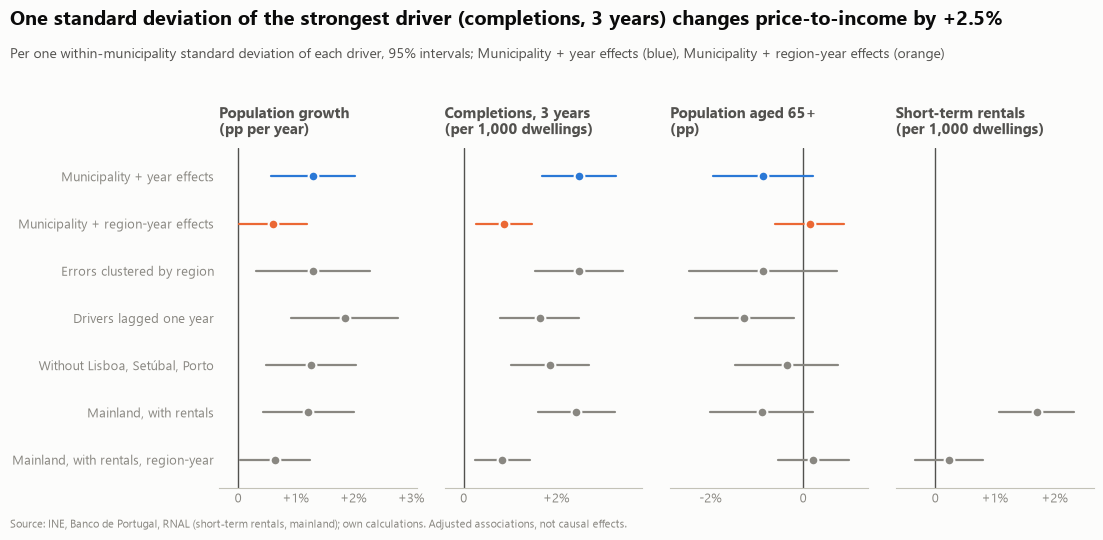

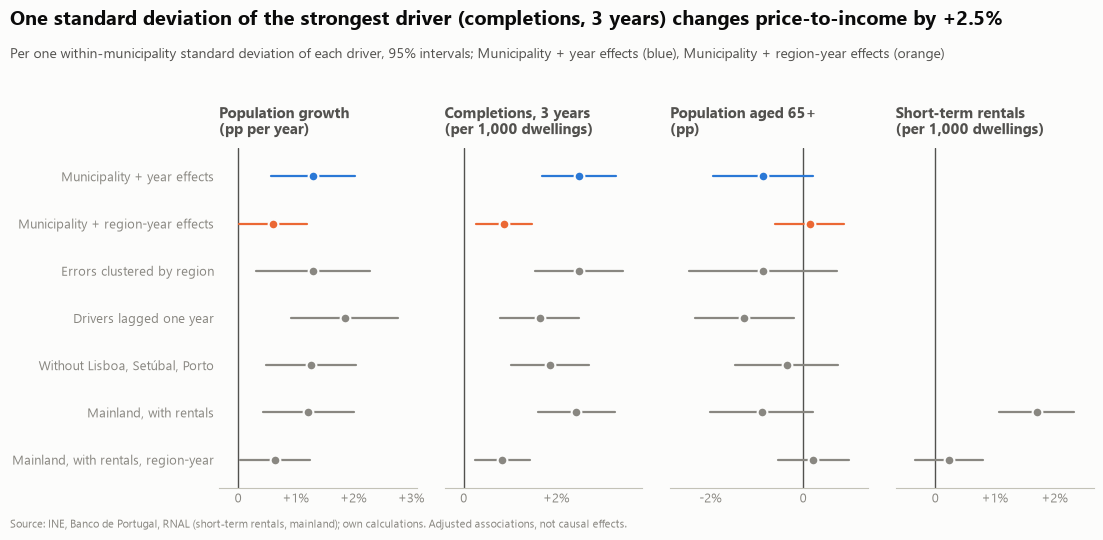

In [4]:
fig = charts.coef_ladder(ladder, pn.LABELS, MAIN, COMPARE, "price-to-income")
style.save_fig(fig, "p2", "fe_coefficients_pti")
fig

## Step 2 — Checks: collinearity and leftover spatial dependence

In [5]:
main_fit = fits[MAIN]
vif = pn.vif(main_fit.sample_frame, X)
print("VIF after removing the fixed effects:", vif.round(2).to_dict())
geo = interim.read("caop_municipalities")
w = spatial.build_weights(geo)
resid = pn.residuals_by_year(main_fit)
resid_moran = spatial.moran_by_year(
    resid.rename(columns={"residual": "resid"}), "resid", w, [2016, 2018, 2020, 2021, 2023]
)
style.save_table(resid_moran, "p2", "fe_residual_moran")
print(resid_moran.round(3).to_string(index=False))

VIF after removing the fixed effects: {'pop_growth_pct': 1.05, 'completions_per_1000': 1.01, 'pop_65plus_pct': 1.05}


 year     I  expected  z_sim  p_sim   n
 2016 0.239    -0.003  6.179  0.001 296
 2018 0.129    -0.003  3.551  0.002 298
 2020 0.056    -0.004  1.457  0.072 278
 2021 0.012    -0.003  0.358  0.364 293
 2023 0.412    -0.003 10.351  0.001 294


## Appendix — The price model with income (why income is not a driver)
Real median income moves slowly (a typical municipality's income changes by about 1% a year, its price by
15%), and municipalities whose prices rose most had the *smallest* income growth. The coefficient on income in a
price regression is therefore negative and large, which reflects convergence in incomes and divergence in
prices, not an effect of income on price.

In [6]:
XP = ["log_income_real", *X]
appendix = pd.concat(
    [
        pn.coef_table(pn.fit(frame, pn.Spec("log_price_real", XP)), "Price, municipality + year"),
        pn.coef_table(
            pn.fit(frame, pn.Spec("log_price_real", XP, effects="region_year")),
            "Price, region-year",
        ),
    ],
    ignore_index=True,
)
style.save_table(appendix, "p2", "fe_regressions_price")
print(appendix[["spec", "term", "coef", "se", "p", "n_obs", "r2"]].round(4).to_string(index=False))

                      spec                 term    coef     se      p  n_obs     r2
Price, municipality + year      log_income_real -1.0291 0.2637 0.0001   2336 0.0578
Price, municipality + year       pop_growth_pct  0.0053 0.0024 0.0291   2336 0.0578
Price, municipality + year completions_per_1000  0.0097 0.0020 0.0000   2336 0.0578
Price, municipality + year       pop_65plus_pct  0.0056 0.0069 0.4189   2336 0.0578
        Price, region-year      log_income_real -0.4913 0.2597 0.0587   2336 0.0097
        Price, region-year       pop_growth_pct  0.0030 0.0025 0.2300   2336 0.0097
        Price, region-year completions_per_1000  0.0035 0.0017 0.0384   2336 0.0097
        Price, region-year       pop_65plus_pct  0.0073 0.0073 0.3156   2336 0.0097


## Findings

1. **Prices, not incomes, drive where affordability worsened (step 0).** Between 2016 and 2024 the median
   municipality's real price per m² rose 51% (log 0.41) and its real income 29% (0.25), so price-to-income rose 19%.
   Across municipalities, 92% of the variance of the deterioration is the price change and 9% the income change
   (dwelling size: −1%). Price growth and income growth are negatively correlated (−0.31): the places where prices
   rose most are not those where incomes rose most.
2. **The observed drivers explain little.** After removing municipality and year effects, population growth,
   recent completions and ageing explain 5% of the remaining variation in log price-to-income (0.9% with
   region-year effects). One within-municipality standard deviation of the strongest driver (completions) goes with
   +2.5% in price-to-income; for population growth it is +1.3%. Collinearity is not the issue (VIF 1.0 to 1.1).
3. **Most of the association is regional.** Adding NUTS 3 × year effects roughly halves the coefficients: population
   growth 0.96 to 0.55 (per pp of annual growth, in % of PTI), completions 1.26 to 0.50 (per completed dwelling per
   1,000), both still positive and significant (p < 0.05). Faster-growing and faster-building municipalities see
   somewhat larger increases than their region, on top of the regional shock.
4. **Construction is positively associated with price-to-income, which is supply responding to price, not building
   raising prices.** It is consistent with developers building where prices are rising. Lagging the drivers a year or excluding Lisboa, Setúbal
   and Porto leaves the signs unchanged. Nothing here estimates what *extra* supply would do; that needs the
   simulator (p4) or a design with exogenous supply.
5. **Short-term rentals: an association that does not survive the region.** On the mainland, 10 more registered
   units per 1,000 dwellings go with +3.2% in price-to-income (p < 0.001), but with region-year effects the
   coefficient is 0.07% per unit (p = 0.43). Rentals concentrate in the Algarve, Lisboa and Porto, where prices rose for
   other reasons too. The series is the stock of units still registered today, which understates the past and so
   overstates its growth (data_quality.md).
6. **Ageing: no robust association** (sign changes across specifications).

**Limits.** The residuals are still spatially correlated in some years (Moran's I 0.01 to 0.41; 0.41 in 2023), so
standard errors clustered by municipality are likely too small; clustering by region (26 clusters) keeps every
conclusion, but few clusters are themselves a caveat. The sample is eight years. Immigration, the largest suspected
demand shock, is not in the panel (the municipal series ends in 2023 and is not yet ingested), so the population
term mixes natural change, internal moves and immigration. Municipal income is smooth and noisy at the same time,
which is why income is decomposed rather than used as a driver.